# Lab 02 — Decision trees and cross-validation

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Put Lectures 8 and 9 into code: learn a decision tree, measure it honestly, and choose its depth
**without looking at the test set**.

| # | Step | Part A — Iris | Part B — NordicMart |
|---|---|---|---|
| 1 | Features, target, baseline | A1 | B1 |
| 2 | Train/test split, and check it | A2 | B2 |
| 3 | Entropy and information gain by hand | A3 | — |
| 4 | A fully grown tree: training error vs test error | A4–A5 | B3 |
| 5 | Error vs depth: underfitting and overfitting | A6 | B4 |
| 6 | Cross-validation, step by step, to choose the depth | A7 | B4–B5 |
| 7 | One final measure on the test set; read the tree | A8 | B6 |
| 8 | Data leakage: a tree that is too good | — | B7 |
| ★ | The Lab 1 recodings: does a tree need them? | — | B8 |

- **Part A (≈ 60 min)** — Iris: the experiment of Lecture 9, number by number.
- **Part B (≈ 45 min)** — NordicMart churn: the same workflow on the customer table of Lab 1.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (notebook good practices, as in Lab 1)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**: you may look at it only where the text says so.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports from scikit-learn: the tree, the tools to split the data, and cross-validation.

In [35]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.0 | pandas 3.0.3


scikit-learn must be version **1.3 or later**: from 1.3 on, decision trees accept missing values (`NaN`), which we need in Part B.

# Part A — Iris

We use the copy of Iris shipped with scikit-learn: the same 150 flowers of Lab 1, with the classes coded as numbers
(0 = setosa, 1 = versicolor, 2 = virginica), as on the slides of Lectures 8 and 9.

## A1. Features, target, baseline

1. Load the data with `load_iris(as_frame=True)`: the result has the attributes `.data` (a DataFrame with the features)
   and `.target` (a Series with the class). Call them `X` and `y`.
1. Shorten the column names by removing the final `" (cm)"`, e.g. with a list comprehension `[c[:-5] for c in X.columns]`.
1. Print the shape of `X` and the class counts of `y`.
1. What is the accuracy of the *majority-class* baseline (Lecture 8)?

In [36]:
# Load dataset
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

# Remove " (cm)" suffix from column names
X.columns = [c[:-5] for c in X.columns]

# Print dimensions and class counts
print("Shape of X:", X.shape)
print("Class counts in y:\n", y.value_counts())

Shape of X: (150, 4)
Class counts in y:
 target
0    50
1    50
2    50
Name: count, dtype: int64


**Convention used in scikit-learn** (and in this course from now on): `X` is the table of features, one row per individual,
shape `(n_samples, n_features)`; `y` is the target, length `n_samples`. Every model has the same two methods:
`fit(X, y)` learns the parameters, `predict(X)` computes the class of new individuals.

## A2. Train/test split

Split Iris **50-50 at random** with [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html),
with `train_size=0.5` and `random_state=10` (the values of Lecture 9). Call the four results `X_train, X_test, y_train, y_test`.

Then check the split: size of the two parts, and class counts in each part.

**Question.** The original file is sorted by class (50 setosa, then 50 versicolor, then 50 virginica).
What would happen if we took the first 75 rows for training and the last 75 for testing?

In [37]:
# 50-50 train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=10)

# Check split dimensions
print(f"training: {X_train.shape} | test: {X_test.shape}")

# Verify class balance across splits
split_check = pd.DataFrame({
    "train": y_train.value_counts(),
    "test": y_test.value_counts()
})
print(split_check)

training: (75, 4) | test: (75, 4)
        train  test
target             
0          27    23
1          23    27
2          25    25


**Answer.** Taking the first 75 rows sequentially would put all 50 setosa and 25 versicolor in the training set, while leaving 25 versicolor and all 50 virginica for the test set. The model would never see virginica during training, resulting in a 0% accuracy on virginica and severe sampling bias.

## A3. Entropy and information gain, in code

### Entropy of a set of labels

Write a function `entropy(labels)` that receives a Series of class labels and returns
$H = -\sum_j p_j \log_2 p_j$, where $p_j$ are the class proportions.

- `labels.value_counts(normalize=True)` gives the proportions
- `np.log2` computes the base-2 logarithm, element by element
- classes with zero count do not appear in `value_counts`, so the convention $0 \log_2 0 = 0$ is automatic

Check it on the weather data of Lecture 8 (9 *yes*, 5 *no*: 0.940 bits), then compute the entropy of `y_train` and `y_test`.

In [38]:
def entropy(labels):
    p = labels.value_counts(normalize=True)
    return -np.sum(p * np.log2(p))

# Verification on weather data
weather = pd.Series(["yes"]*9 + ["no"]*5)
print(f"weather data: {entropy(weather):.3f} bits")
print(f"training: {entropy(y_train):.3f} | test set: {entropy(y_test):.3f}")

weather data: 0.940 bits
training: 1.582 | test set: 1.582


### Information gain of a threshold

Write a function `info_gain(x, labels, t)`: `x` is a numeric feature, `labels` the classes of the same rows,
`t` a threshold. It returns $IG = H(\text{labels}) - \big(H(\text{left})\,n_{left} + H(\text{right})\,n_{right}\big) / n$,
where *left* are the rows with `x < t` and *right* those with `x >= t`.
Use a **boolean mask**: `labels[x < t]` selects the labels of the rows where the condition is true.

Check: on the training set, the threshold 5.75 on `sepal length` must give a gain of 0.61 (Lecture 9).

In [39]:
def info_gain(x, labels, t):
    H_parent = entropy(labels)
    
    left_mask = x < t
    right_mask = x >= t
    
    labels_left = labels[left_mask]
    labels_right = labels[right_mask]
    
    n = len(labels)
    n_left = len(labels_left)
    n_right = len(labels_right)
    
    H_left = entropy(labels_left) if n_left > 0 else 0
    H_right = entropy(labels_right) if n_right > 0 else 0
    
    return H_parent - (H_left * n_left + H_right * n_right) / n

# Verification on training set
print(f"Gain for sepal length at 5.75: {info_gain(X_train['sepal length'], y_train, 5.75):.2f}")

Gain for sepal length at 5.75: 0.61


### The best threshold of every attribute

The candidate thresholds of a numeric attribute are the **midpoints** between consecutive distinct values (Lecture 8).
Write a function `best_split(x, labels)` that tries all of them and returns the best threshold and its gain.
Hints: `np.sort(x.unique())` gives the distinct values in order; if `v` is that array, `(v[:-1] + v[1:]) / 2` are the midpoints.

Apply it to the four features of the training set and collect the results in a DataFrame.
Compare with the four frames *Predicting attribute* of Lecture 9.

In [40]:
def best_split(x, labels):
    v = np.sort(x.unique())
    thresholds = (v[:-1] + v[1:]) / 2
    
    best_t = None
    best_ig = -1
    
    for t in thresholds:
        ig = info_gain(x, labels, t)
        if ig > best_ig:
            best_ig = ig
            best_t = t
            
    return best_t, best_ig

results = []
for col in X_train.columns:
    t, ig = best_split(X_train[col], y_train)
    results.append({"best threshold": t, "information gain": ig})

df_results = pd.DataFrame(results, index=X_train.columns)
display(df_results)

,best threshold,information gain
sepal length,5.75,0.610
sepal width,3.25,0.416
petal length,2.60,0.943
petal width,0.75,0.943


**Answer.** *Write your answer here (double-click to edit).*

### Information gain as a function of the threshold ★

Plot the gain of every candidate threshold of `petal width` (x axis: threshold, y axis: gain).
Why is the gain low at both ends?

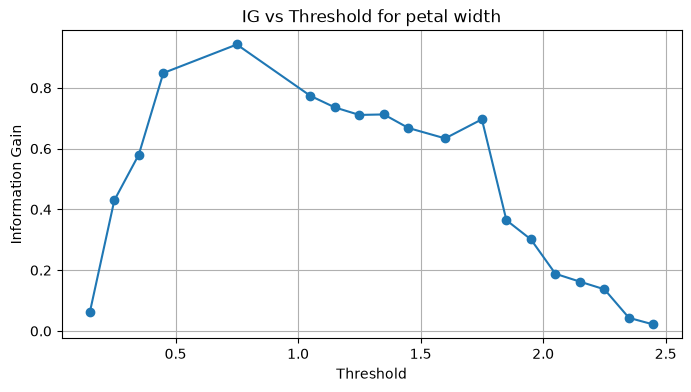

In [41]:
v = np.sort(X_train["petal width"].unique())
thresholds = (v[:-1] + v[1:]) / 2
gains = [info_gain(X_train["petal width"], y_train, t) for t in thresholds]

plt.plot(thresholds, gains, marker='o')
plt.xlabel("Threshold")
plt.ylabel("Information Gain")
plt.title("IG vs Threshold for petal width")
plt.grid(True)
plt.show()

**Answer.** *Write your answer here (double-click to edit).*

## A4. A fully grown tree on the original training set

1. Create a [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
   with `criterion="entropy"` (the default is Gini, Lecture 9) and `random_state=10`, and learn it with `fit` on the training set.
   Without other hyperparameters, the tree grows until its leaves are pure.
1. Draw it with `plot_tree(model, feature_names=..., class_names=..., filled=True)`.
1. Print its depth (`get_depth()`) and number of leaves (`get_n_leaves()`).

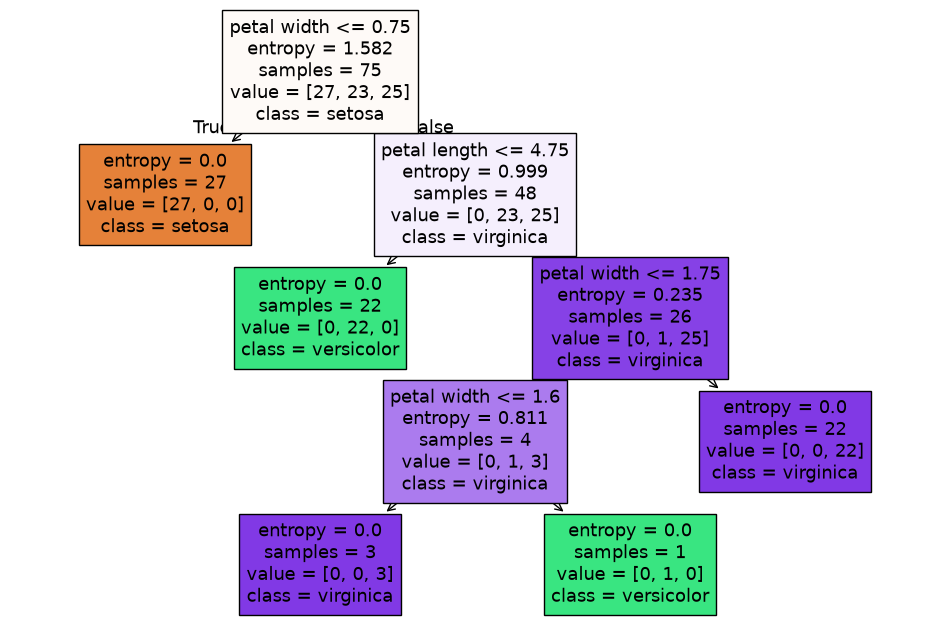

depth: 4 | leaves: 5


In [42]:
# Helper function to count misclassifications
def errors(model, X, y):
    return (model.predict(X) != y).sum()

# 1. Model instantiation and fitting
model = DecisionTreeClassifier(criterion="entropy", random_state=10)
model.fit(X_train, y_train)

# 2. Plotting the tree structure
plt.figure(figsize=(12, 8))
plot_tree(model, feature_names=X.columns, class_names=["setosa", "versicolor", "virginica"], filled=True)
plt.show()

# 3. Print depth and leaf count
print(f"depth: {model.get_depth()} | leaves: {model.get_n_leaves()}")

### Training error and test error

Compute the predictions on the training set and on the test set, and for each one the **number of errors** and the **error rate**.

- `model.predict(X)` returns the predicted classes
- `(predicted != y).sum()` counts the errors; `accuracy_score(y, predicted)` gives the accuracy, and the error rate is 1 − accuracy
- `model.score(X, y)` computes the accuracy in one call

Since we will repeat this many times, write a small function `errors(model, X, y)` returning the number of errors.

In [43]:
train_err_count = errors(model, X_train, y_train)
test_err_count = errors(model, X_test, y_test)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print(f"Training Errors: {train_err_count} | Error Rate: {1 - train_acc:.3f} | Accuracy: {train_acc:.3f}")
print(f"Test Errors:     {test_err_count} | Error Rate: {1 - test_acc:.3f} | Accuracy: {test_acc:.3f}")

Training Errors: 0 | Error Rate: 0.000 | Accuracy: 1.000
Test Errors:     6 | Error Rate: 0.080 | Accuracy: 0.920


**Answer.** *Write your answer here (double-click to edit).*

## A5. The altered training set of Lecture 9

To make noise and overfitting visible, Lecture 9 altered two training flowers:

- flower **125** (a virginica): label changed to 0 (setosa)
- flower **113** (a virginica): measurements overwritten with those of flower 125, label changed to 1 (versicolor)

1. Create the copies `X_train_alt` and `y_train_alt` (use `.copy()`: the original training set must stay untouched)
   and apply the two changes with `.loc[...]`: the numbers are row **labels** (the index of the original data set), not positions.
1. Check the class counts: Lecture 9 says 28/24/23.
1. Learn a fully grown tree `tree_alt` (same hyperparameters as before) on the altered set; draw it; count training and test errors.

Altered class counts:
target
0    28
1    24
2    23
Name: count, dtype: int64


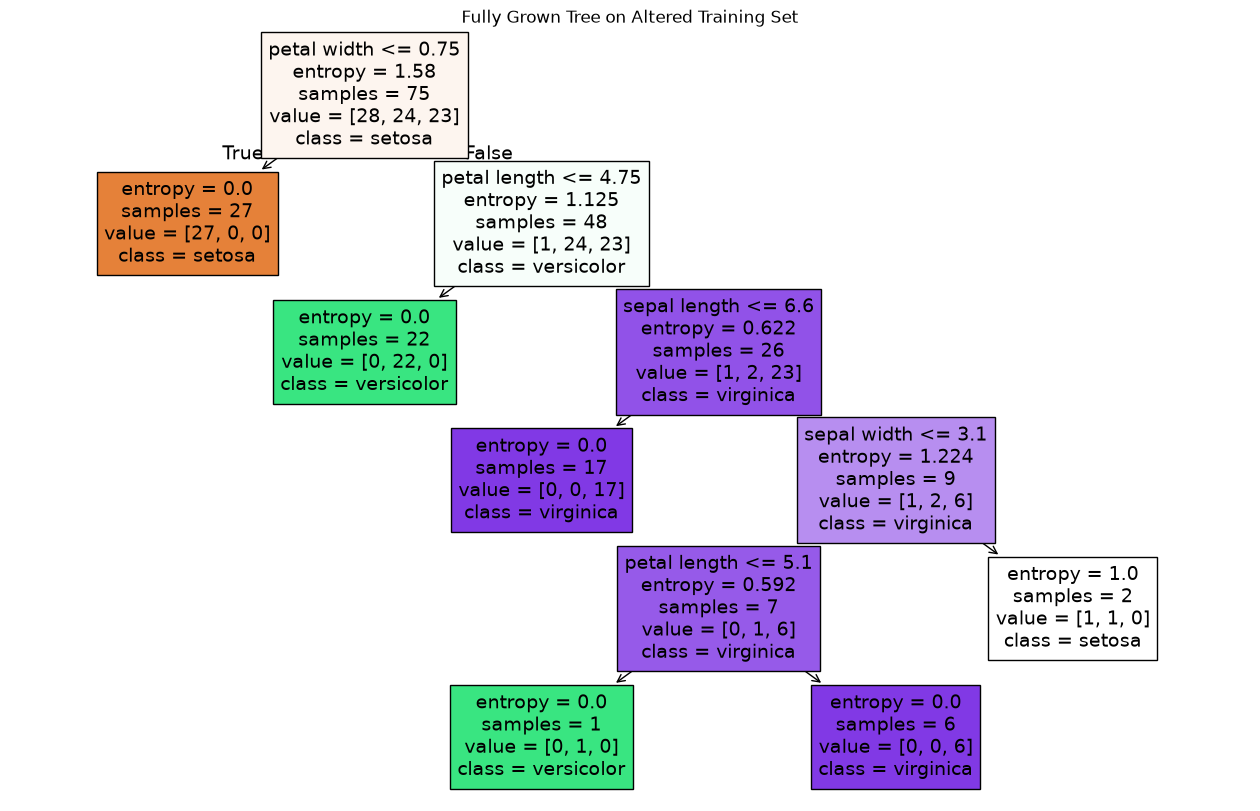

Training errors (altered): 1
Test errors (altered):     12


In [44]:
# 1. Create copies and apply alterations
X_train_alt = X_train.copy()
y_train_alt = y_train.copy()

# Relabel flower 125 (virginica) to 0 (setosa)
y_train_alt.loc[125] = 0

# Copy measurements of flower 125 to flower 113, relabel 113 to 1 (versicolor)
X_train_alt.loc[113] = X_train.loc[125]
y_train_alt.loc[113] = 1

# 2. Verify class distribution
print("Altered class counts:")
print(y_train_alt.value_counts().sort_index())

# 3. Fit unconstrained tree on altered set
tree_alt = DecisionTreeClassifier(criterion="entropy", random_state=10)
tree_alt.fit(X_train_alt, y_train_alt)

plt.figure(figsize=(16, 10))
plot_tree(
    tree_alt, 
    feature_names=X_train_alt.columns, 
    class_names=['setosa', 'versicolor', 'virginica'], 
    filled=True
)
plt.title("Fully Grown Tree on Altered Training Set")
plt.show()

print(f"Training errors (altered): {errors(tree_alt, X_train_alt, y_train_alt)}")
print(f"Test errors (altered):     {errors(tree_alt, X_test, y_test)}")

In [45]:
# your code here


### Inside the tree: the arrays of `tree_`

The learned tree is stored in the attribute `tree_` as parallel arrays, one position per node (Lecture 9, *internal representation*):
`children_left`, `children_right` (−1 for a leaf), `feature` (index of the tested column), `threshold`,
`n_node_samples`, `impurity`.

1. Put these arrays into a DataFrame, one row per node; replace the feature index with the column name, and show
   `-` for feature and threshold in the leaves.
1. Which leaf is impure? Which training flowers reach it? `model.apply(X)` returns, for every row, the node (leaf) where it ends.

In [46]:
tree_data = tree_alt.tree_

df_tree = pd.DataFrame({
    'node': range(tree_data.node_count),
    'left_child': tree_data.children_left,
    'right_child': tree_data.children_right,
    'feature': tree_data.feature,
    'threshold': tree_data.threshold,
    'n_node_samples': tree_data.n_node_samples,
    'impurity': tree_data.impurity
})

is_leaf = df_tree['left_child'] == -1
feature_names = X_train.columns
df_tree['feature'] = np.where(is_leaf, '-', [feature_names[i] if i >= 0 else '-' for i in df_tree['feature']])
df_tree['threshold'] = np.where(is_leaf, '-', df_tree['threshold'])

print("Tree DataFrame:")
display(df_tree)

# Identify impure leaf node
impure_leaves = df_tree[(is_leaf) & (df_tree['impurity'] > 0)]
print("\nImpure leaves:")
display(impure_leaves)

impure_leaf_node = impure_leaves['node'].iloc[0]
leaf_indices = tree_alt.apply(X_train_alt)
impure_flowers = X_train_alt[leaf_indices == impure_leaf_node]

print(f"\nTraining flowers in impure leaf (Node {impure_leaf_node}):")
display(impure_flowers)
print("\nAltered labels for these flowers:")
print(y_train_alt.loc[impure_flowers.index])

Tree DataFrame:


,node,left_child,right_child,feature,threshold,n_node_samples,impurity
0,0,1,2,petal width,0.75,75,1.580
1,1,-1,-1,-,-,27,0.000
2,2,3,4,petal length,4.75,48,1.125
3,3,-1,-1,-,-,22,0.000
4,4,5,6,sepal length,6.599999904632568,26,0.622
5,5,-1,-1,-,-,17,0.000
6,6,7,10,sepal width,3.100000023841858,9,1.224
7,7,8,9,petal length,5.099999904632568,7,0.592
8,8,-1,-1,-,-,1,0.000
9,9,-1,-1,-,-,6,0.000



Impure leaves:


,node,left_child,right_child,feature,threshold,n_node_samples,impurity
10,10,-1,-1,-,-,2,1.0



Training flowers in impure leaf (Node 10):


,sepal length,sepal width,petal length,petal width
113,7.2,3.2,6.0,1.8
125,7.2,3.2,6.0,1.8



Altered labels for these flowers:
113    1
125    0
Name: target, dtype: int64


In [47]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## A6. Error vs depth: underfitting and overfitting

Learn trees on the **altered** training set with `max_depth` from 1 to 5. For each depth, record the training error rate
and the test error rate in a DataFrame, then plot the two curves (x: depth, y: error rate).
Compare with the figure *Errors and tree depth* of Lecture 9.

,train_error_rate,test_error_rate
max_depth,,
1,0.320,0.333
2,0.040,0.080
3,0.040,0.080
4,0.027,0.173
5,0.013,0.160


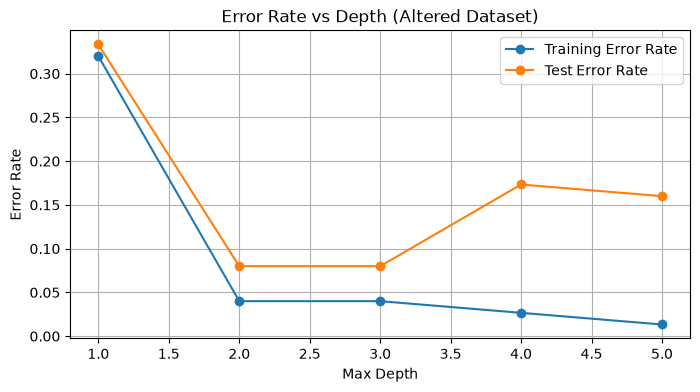

In [48]:
train_error_rates = []
test_error_rates = []
depths = range(1, 6)

for d in depths:
    clf = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=10)
    clf.fit(X_train_alt, y_train_alt)
    
    train_err = 1 - accuracy_score(y_train_alt, clf.predict(X_train_alt))
    test_err = 1 - accuracy_score(y_test, clf.predict(X_test))
    
    train_error_rates.append(train_err)
    test_error_rates.append(test_err)

df_rates = pd.DataFrame({
    "max_depth": depths,
    "train_error_rate": train_error_rates,
    "test_error_rate": test_error_rates
}).set_index("max_depth")

display(df_rates.round(3))

plt.plot(depths, train_error_rates, label='Training Error Rate', marker='o')
plt.plot(depths, test_error_rates, label='Test Error Rate', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('Error Rate')
plt.legend()
plt.title('Error Rate vs Depth (Altered Dataset)')
plt.grid(True)
plt.show()

**Question.** Where does the tree underfit, where does it overfit? Which depth would you choose?
And now the important question: **are you allowed to choose it this way?**

**Answer.** *Write your answer here (double-click to edit).*

## A7. Cross-validation, step by step

From now on the test set is **locked**. Everything happens on the 75 flowers of the (altered) training set.

### Step 1 — the folds

[`StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
cuts the training set into $k$ folds keeping the class proportions in each fold (*stratified*, Lecture 8).
Create `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`.

`cv.split(X, y)` produces, for each round, two arrays of **positions**: the rows used to learn and the rows held out.
Loop over the rounds with `enumerate`, and for each one print the number of rows of the two parts and the class counts
of the held-out fold. Use `.iloc` to select rows by position.

In [49]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_alt, y_train_alt)):
    num_train = len(train_idx)
    num_val = len(val_idx)
    y_val_fold = y_train_alt.iloc[val_idx]
    
    print(f"Fold {fold + 1}:")
    print(f"  Training samples: {num_train} | Validation samples: {num_val}")
    print(f"  Validation class distribution:\n{y_val_fold.value_counts().sort_index().to_string()}\n")

Fold 1:
  Training samples: 60 | Validation samples: 15
  Validation class distribution:
target
0    6
1    4
2    5

Fold 2:
  Training samples: 60 | Validation samples: 15
  Validation class distribution:
target
0    5
1    5
2    5

Fold 3:
  Training samples: 60 | Validation samples: 15
  Validation class distribution:
target
0    5
1    5
2    5

Fold 4:
  Training samples: 60 | Validation samples: 15
  Validation class distribution:
target
0    6
1    5
2    4

Fold 5:
  Training samples: 60 | Validation samples: 15
  Validation class distribution:
target
0    6
1    5
2    4



**Question.** How many times is each flower held out? How many times is it used for learning?

**Answer.** *Write your answer here (double-click to edit).*

### Step 2 — one model per round, by hand

For a tree with `max_depth=2`: in each round learn a new tree on the learning part, compute its accuracy on the held-out fold,
and collect the five accuracies in a list. Print them, then their **mean** and **standard deviation**.

In [50]:
accuracies_hand = []

for train_idx, val_idx in cv.split(X_train_alt, y_train_alt):
    X_f_train, y_f_train = X_train_alt.iloc[train_idx], y_train_alt.iloc[train_idx]
    X_f_val, y_f_val = X_train_alt.iloc[val_idx], y_train_alt.iloc[val_idx]
    
    clf_cv = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10)
    clf_cv.fit(X_f_train, y_f_train)
    
    acc = accuracy_score(y_f_val, clf_cv.predict(X_f_val))
    accuracies_hand.append(acc)

print(f"Fold accuracies: {np.round(accuracies_hand, 3)}")
print(f"Mean accuracy: {np.mean(accuracies_hand):.3f}")
print(f"Standard deviation: {np.std(accuracies_hand):.3f}")

Fold accuracies: [0.933 0.933 1.    1.    0.933]
Mean accuracy: 0.960
Standard deviation: 0.033


### Step 3 — the same in one line

[`cross_val_score(model, X, y, cv=cv)`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
does exactly the loop above and returns the five scores (accuracy, for a classifier). Check that you get the same numbers.

In [51]:
clf_step3 = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10)
scores_step3 = cross_val_score(clf_step3, X_train_alt, y_train_alt, cv=cv)

print(f"Fold accuracies (cross_val_score): {np.round(scores_step3, 3)}")
print(f"Mean accuracy: {scores_step3.mean():.3f}")
print(f"Standard deviation: {scores_step3.std():.3f}")

Fold accuracies (cross_val_score): [0.933 0.933 1.    1.    0.933]
Mean accuracy: 0.960
Standard deviation: 0.033


### Step 4 — choose the depth with cross-validation

For every `max_depth` from 1 to 5, compute mean and standard deviation of the 5-fold cross-validation accuracy
on the altered training set. Use **the same `cv` object** for all depths: same folds, fair comparison.
Collect the results in a DataFrame next to the test errors of A6 (which we computed, but **must not use** to choose).

In [52]:
depths = range(1, 6)
cv_means = []
cv_stds = []
test_errors = []
test_accuracies = []

for d in depths:
    clf = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=10)
    
    scores = cross_val_score(clf, X_train_alt, y_train_alt, cv=cv)
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    
    # Train on full altered training set to compute reference test metric
    clf.fit(X_train_alt, y_train_alt)
    y_pred_test = clf.predict(X_test)
    
    test_errors.append(errors(clf, X_test, y_test))
    test_accuracies.append(accuracy_score(y_test, y_pred_test))

df_cv_results = pd.DataFrame({
    'max_depth': depths,
    'cv_mean_acc': cv_means,
    'cv_std_acc': cv_stds,
    'test_errors': test_errors,
    'test_accuracy': test_accuracies
}).set_index('max_depth')

print(df_cv_results.round(3))

           cv_mean_acc  cv_std_acc  test_errors  test_accuracy
max_depth                                                     
1                 0.68       0.027           25          0.667
2                 0.96       0.033            6          0.920
3                 0.96       0.033            6          0.920
4                 0.92       0.078           13          0.827
5                 0.92       0.078           12          0.840


**Question.** Which depth does cross-validation choose? If two depths are equally good, which one do you prefer, and why?

**Answer.** *Write your answer here (double-click to edit).*

### Step 5 — the final model, and the one look at the test set

The chosen *way of building* the model is "tree with `max_depth=2`". Learn it on the **whole** training set
(not on one of the folds), and only now measure it, **once**, on the test set.

In [53]:
final_tree = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10)
final_tree.fit(X_train_alt, y_train_alt)

final_test_acc = accuracy_score(y_test, final_tree.predict(X_test))
final_test_errs = errors(final_tree, X_test, y_test)

print(f"Final Test Accuracy: {final_test_acc:.3f}")
print(f"Final Test Errors: {final_test_errs} out of {len(y_test)}")

Final Test Accuracy: 0.920
Final Test Errors: 6 out of 75


**Answer.** *Write your answer here (double-click to edit).*

### Why shuffle and stratify? ★

Run `cross_val_score` of a fully grown tree on the **whole** Iris data set (`X`, `y`, which are sorted by class) with
`cv=KFold(3)` — no shuffling — and then with `cv=StratifiedKFold(3, shuffle=True, random_state=SEED)`. Explain the difference.

In [54]:
X_full, y_full = load_iris(return_X_y=True)
tree_full = DecisionTreeClassifier(criterion="entropy", random_state=SEED)

# KFold without shuffling on sorted target labels
kf = KFold(n_splits=3)
scores_kf = cross_val_score(tree_full, X_full, y_full, cv=kf)

# StratifiedKFold with shuffling
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
scores_skf = cross_val_score(tree_full, X_full, y_full, cv=skf)

print(f"KFold (no shuffle) accuracies: {scores_kf}")
print(f"KFold (no shuffle) mean accuracy: {scores_kf.mean():.3f}\n")

print(f"StratifiedKFold (shuffled) accuracies: {scores_skf}")
print(f"StratifiedKFold (shuffled) mean accuracy: {scores_skf.mean():.3f}")

KFold (no shuffle) accuracies: [0. 0. 0.]
KFold (no shuffle) mean accuracy: 0.000

StratifiedKFold (shuffled) accuracies: [1.   0.92 0.94]
StratifiedKFold (shuffled) mean accuracy: 0.953


**Answer.** *Write your answer here (double-click to edit).*

### A cross-validation estimate also varies ★

Repeat Step 4 for depth 2 and depth 4 with five different `random_state` values of `StratifiedKFold` (e.g. 0 to 4).
How much does the mean change? What does it tell you about comparing two depths whose CV means differ by 0.01?

In [55]:
for depth in [2, 4]:
    seed_means = []
    for seed_val in range(5):
        cv_var = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed_val)
        clf_var = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=10)
        score = cross_val_score(clf_var, X_train_alt, y_train_alt, cv=cv_var).mean()
        seed_means.append(score)
    print(f"max_depth={depth} CV means (seeds 0-4): {np.round(seed_means, 3)} | Mean across seeds: {np.mean(seed_means):.3f}")

max_depth=2 CV means (seeds 0-4): [0.96  0.96  0.96  0.96  0.933] | Mean across seeds: 0.955
max_depth=4 CV means (seeds 0-4): [0.933 0.947 0.96  0.947 0.92 ] | Mean across seeds: 0.941


**Answer.** *Write your answer here (double-click to edit).*

# Part B — NordicMart: a churn tree

The customer table of Lecture 6 and Lab 1: 3000 customers, target `churned` (12% churners).
The setup is the same as Lecture 10, so your numbers will appear on Wednesday's slides.

## B1. Features, target, baseline

1. Load the file into `df` (raw table, not modified).
1. Features: `tier`, `age`, `days_since_last_buy`, `annual_spend`, `web_sessions_month`, `tickets_90d`.
   `customer_id` is an identifier, `postcode` is constant (Lab 1): neither is a feature. Target: `churned`.
1. scikit-learn trees need numeric features: code `tier`, which is ordinal, as Basic = 0, Silver = 1, Gold = 2 with
   `.map({...})`. The general treatment of categorical attributes comes in session 16.
1. Missing values stay `NaN`: the tree handles them (see B6). Count them per column.
1. Baseline accuracy?

In [56]:
# 1. Load the raw data into df
df = pd.read_csv(NORDICMART_FILE)

# 2 & 3. Select features and ordinally encode 'tier'
feature_cols = [
    "tier",
    "age",
    "days_since_last_buy",
    "annual_spend",
    "web_sessions_month",
    "tickets_90d",
]
tier_map = {"Basic": 0, "Silver": 1, "Gold": 2}

X_nm = df[feature_cols].copy()
X_nm["tier"] = X_nm["tier"].map(tier_map)
y_nm = df["churned"]

# 4. Count missing values (NaN) per feature
print("Missing values per feature column:")
print(X_nm.isna().sum())

# 5. Calculate majority-class baseline accuracy
majority_class_acc = y_nm.value_counts(normalize=True).max()
print(f"\nMajority-class Baseline Accuracy: {majority_class_acc:.3f} ({majority_class_acc:.1%})")

Missing values per feature column:
tier                     0
age                    303
days_since_last_buy      0
annual_spend             0
web_sessions_month     540
tickets_90d              0
dtype: int64

Majority-class Baseline Accuracy: 0.880 (88.0%)


## B2. A stratified train/test split

With an imbalanced target a plain random split can, by chance, put a different share of churners in the two parts.
Split 70/30 with `test_size=0.3`, `stratify=yn` and `random_state=SEED`, and check size and churn rate of the two parts.

In [57]:
# Perform 70/30 stratified train/test split
X_train_nm, X_test_nm, y_train_nm, y_test_nm = train_test_split(
    X_nm, y_nm, test_size=0.3, stratify=y_nm, random_state=SEED
)

# Print set dimensions
print(f"Training set shape: {X_train_nm.shape} | Test set shape: {X_test_nm.shape}")

# Compute churn rates (mean of binary 0/1 target)
train_churn_rate = y_train_nm.mean()
test_churn_rate = y_test_nm.mean()

print(f"Training set churn rate: {train_churn_rate:.3f} ({train_churn_rate:.1%})")
print(f"Test set churn rate:     {test_churn_rate:.3f} ({test_churn_rate:.1%})")

# Display breakdown table
split_summary = pd.DataFrame({
    "Total Samples": [len(y_train_nm), len(y_test_nm)],
    "Churners (1)": [y_train_nm.sum(), y_test_nm.sum()],
    "Non-Churners (0)": [(y_train_nm == 0).sum(), (y_test_nm == 0).sum()],
    "Churn Rate": [train_churn_rate, test_churn_rate]
}, index=["Train (70%)", "Test (30%)"])

display(split_summary)

Training set shape: (2100, 6) | Test set shape: (900, 6)
Training set churn rate: 0.120 (12.0%)
Test set churn rate:     0.120 (12.0%)


,Total Samples,Churners (1),Non-Churners (0),Churn Rate
Train (70%),2100,252,1848,0.12
Test (30%),900,108,792,0.12


## B3. A fully grown tree

Learn a `DecisionTreeClassifier(random_state=0)` (default criterion: Gini) on the training part.
Print depth and number of leaves, training and test accuracy, and compare with the baseline.
Then show the cross-table of actual vs predicted classes on the test set (`pd.crosstab`, as in Lab 1).

In [58]:
# 1. Instantiate and fit unconstrained DecisionTreeClassifier (default criterion: Gini)
tree_nm_full = DecisionTreeClassifier(random_state=0)
tree_nm_full.fit(X_train_nm, y_train_nm)

# 2. Get tree structure metrics
depth = tree_nm_full.get_depth()
leaves = tree_nm_full.get_n_leaves()

# Predict on train and test sets
y_train_pred = tree_nm_full.predict(X_train_nm)
y_test_pred = tree_nm_full.predict(X_test_nm)

# 3. Calculate accuracies
train_acc = accuracy_score(y_train_nm, y_train_pred)
test_acc = accuracy_score(y_test_nm, y_test_pred)
baseline_acc = (y_test_nm == 0).mean()

print(f"Tree Depth: {depth}")
print(f"Number of Leaves: {leaves}\n")
print(f"Training Accuracy: {train_acc:.3f} ({train_acc:.1%})")
print(f"Test Accuracy:     {test_acc:.3f} ({test_acc:.1%})")
print(f"Baseline Accuracy: {baseline_acc:.3f} ({baseline_acc:.1%})\n")

# 5. Confusion matrix (cross-table of actual vs predicted classes on the test set)
ct = pd.crosstab(
    y_test_nm, 
    y_test_pred, 
    rownames=["Actual"], 
    colnames=["Predicted"],
    margins=True
)
display(ct)

Tree Depth: 23
Number of Leaves: 289

Training Accuracy: 1.000 (100.0%)
Test Accuracy:     0.824 (82.4%)
Baseline Accuracy: 0.880 (88.0%)



Predicted,0,1,All
Actual,,,
0,705,87,792
1,71,37,108
All,776,124,900


**Answer.** *Write your answer here (double-click to edit).*

## B4. Choosing the depth with cross-validation

Use [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html):
like `cross_val_score`, but it returns a dictionary and, with `return_train_score=True`, also the accuracy
on the learning part of each round (`"train_score"`) besides the held-out one (`"test_score"`).

1. Create `cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)` (the folds of Lecture 10).
1. For `max_depth` in `[1, 2, 3, 4, 5, 6, 8, 10, 12, None]` record: mean training accuracy, mean and std of the held-out accuracy.
1. Plot the two curves; draw the held-out one with error bars (`ax.errorbar(..., yerr=std)`) and the baseline as a horizontal line.

,max_depth,train_acc_mean,val_acc_mean,val_acc_std
0,1,0.881,0.879,0.004
1,2,0.895,0.887,0.008
2,3,0.899,0.888,0.008
3,4,0.906,0.890,0.006
4,5,0.915,0.886,0.010
5,6,0.926,0.880,0.013
6,8,0.944,0.880,0.009
7,10,0.964,0.863,0.015
8,12,0.979,0.854,0.017
9,None,1.000,0.830,0.020


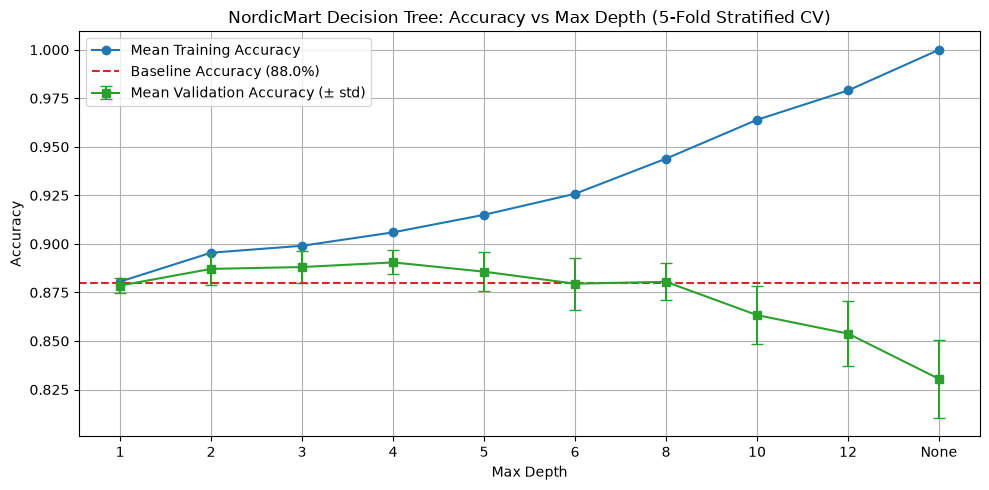

In [59]:
# 1. Create the StratifiedKFold cross-validator
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

depth_values = [1, 2, 3, 4, 5, 6, 8, 10, 12, None]
depth_labels = [str(d) if d is not None else "None" for d in depth_values]

train_acc_means = []
val_acc_means = []
val_acc_stds = []

# 2. Iterate through candidate max_depth values using cross_validate
for d in depth_values:
    clf = DecisionTreeClassifier(random_state=0, max_depth=d)
    res = cross_validate(clf, X_train_nm, y_train_nm, cv=cv_n, return_train_score=True)
    
    train_acc_means.append(res["train_score"].mean())
    val_acc_means.append(res["test_score"].mean())
    val_acc_stds.append(res["test_score"].std())

# Combine metrics into a summary DataFrame
df_cv_depth = pd.DataFrame({
    "max_depth": depth_labels,
    "train_acc_mean": train_acc_means,
    "val_acc_mean": val_acc_means,
    "val_acc_std": val_acc_stds
})
display(df_cv_depth.round(3))

# 3. Plotting error bars and baseline
fig, ax = plt.subplots(figsize=(10, 5))

# Plot training accuracy
ax.plot(depth_labels, train_acc_means, marker="o", label="Mean Training Accuracy", color="tab:blue")

# Plot held-out validation accuracy with error bars
ax.errorbar(
    depth_labels, 
    val_acc_means, 
    yerr=val_acc_stds, 
    marker="s", 
    capsize=4, 
    label="Mean Validation Accuracy (± std)", 
    color="tab:green"
)

# Plot majority-class baseline as a horizontal line
baseline = (y_train_nm == 0).mean()
ax.axhline(y=baseline, color="tab:red", linestyle="--", label=f"Baseline Accuracy ({baseline:.1%})")

ax.set_xlabel("Max Depth")
ax.set_ylabel("Accuracy")
ax.set_title("NordicMart Decision Tree: Accuracy vs Max Depth (5-Fold Stratified CV)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

In [60]:
# your code here


**Question.** Which depth does cross-validation choose? How far is it from the baseline? How large is the standard deviation
compared with the differences between depths 2 and 5?

**Answer.** *Write your answer here (double-click to edit).*

## B5. Another hyperparameter: `min_samples_leaf` ★

Keep `max_depth=4` and try `min_samples_leaf` in `[1, 10, 30, 100]` (the minimum number of training customers in a leaf,
one of the meanings of "the data set is small" in Lecture 9). Use the same `cv_n`.

In [61]:
# Evaluate min_samples_leaf with fixed max_depth=4
min_samples_leaf_values = [1, 10, 30, 100]

train_acc_means_leaf = []
val_acc_means_leaf = []
val_acc_stds_leaf = []

# Perform 5-fold cross-validation for each min_samples_leaf value
for leaf_size in min_samples_leaf_values:
    clf = DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=leaf_size,
        random_state=0
    )
    res = cross_validate(clf, X_train_nm, y_train_nm, cv=cv_n, return_train_score=True)
    
    train_acc_means_leaf.append(res["train_score"].mean())
    val_acc_means_leaf.append(res["test_score"].mean())
    val_acc_stds_leaf.append(res["test_score"].std())

# Combine results into a DataFrame
df_cv_leaf = pd.DataFrame({
    "min_samples_leaf": min_samples_leaf_values,
    "train_acc_mean": train_acc_means_leaf,
    "val_acc_mean": val_acc_means_leaf,
    "val_acc_std": val_acc_stds_leaf
}).set_index("min_samples_leaf")

display(df_cv_leaf.round(3))

,train_acc_mean,val_acc_mean,val_acc_std
min_samples_leaf,,,
1,0.906,0.890,0.006
10,0.904,0.888,0.008
30,0.896,0.888,0.008
100,0.882,0.882,0.010


**Answer.** *Write your answer here (double-click to edit).*

## B6. The final model: one test measure, and reading the tree

1. Learn the tree with the chosen depth on the **whole** training part; compute the test accuracy and the cross-table, **once**.
1. Print the first two levels of the tree as text with `export_text(model, feature_names=FEATURES, max_depth=2)`.

In [62]:
# 1. Train the final model with the chosen optimal depth (max_depth=4) on the full training set
final_depth = 4
final_tree_nm = DecisionTreeClassifier(
    criterion="gini", 
    max_depth=final_depth, 
    random_state=0
)
final_tree_nm.fit(X_train_nm, y_train_nm)

# Evaluate performance exactly once on the locked test set
y_test_pred_final = final_tree_nm.predict(X_test_nm)
final_test_acc_nm = accuracy_score(y_test_nm, y_test_pred_final)
baseline_test_acc = (y_test_nm == 0).mean()

print(f"Final Test Accuracy (max_depth={final_depth}): {final_test_acc_nm:.3f} ({final_test_acc_nm:.1%})")
print(f"Baseline Test Accuracy:                 {baseline_test_acc:.3f} ({baseline_test_acc:.1%})\n")

# Generate confusion matrix on test set
ct_final = pd.crosstab(
    y_test_nm, 
    y_test_pred_final, 
    rownames=["Actual"], 
    colnames=["Predicted"], 
    margins=True
)
print("Test Set Cross-Table:")
display(ct_final)

# 2. Export and print the top two levels of the learned tree structure
tree_rules = export_text(
    final_tree_nm, 
    feature_names=feature_cols, 
    max_depth=2
)
print("\nFirst two levels of the Decision Tree:")
print(tree_rules)

Final Test Accuracy (max_depth=4): 0.879 (87.9%)
Baseline Test Accuracy:                 0.880 (88.0%)

Test Set Cross-Table:


Predicted,0,1,All
Actual,,,
0,768,24,792
1,85,23,108
All,853,47,900



First two levels of the Decision Tree:
|--- days_since_last_buy <= 111.50
|   |--- web_sessions_month <= inf
|   |   |--- annual_spend <= 5778.30
|   |   |   |--- truncated branch of depth 2
|   |   |--- annual_spend >  5778.30
|   |   |   |--- class: 1
|   |--- web_sessions_month >  inf
|   |   |--- days_since_last_buy <= 52.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  52.50
|   |   |   |--- truncated branch of depth 2
|--- days_since_last_buy >  111.50
|   |--- web_sessions_month <= 0.50
|   |   |--- age <= 59.00
|   |   |   |--- truncated branch of depth 2
|   |   |--- age >  59.00
|   |   |   |--- truncated branch of depth 2
|   |--- web_sessions_month >  0.50
|   |   |--- days_since_last_buy <= 733.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  733.50
|   |   |   |--- truncated branch of depth 2



In [63]:
# Map the lab variables to our NordicMart dataset
Xn = X_nm
yn = y_nm

**Questions.**

1. Test accuracy vs CV estimate vs baseline: what do you conclude? How many churners does the tree find?
1. Which attribute is at the root? Does it agree with what EDA suggested in Lab 1?
1. Two tests look strange: `web_sessions_month <= inf` and `days_since_last_buy > 733.50`. What are they doing?
   (Hint: what is in Lab 1's EDA log about missing sessions and the value 999?)

**Answer.** *Write your answer here (double-click to edit).*

## B7. Data leakage: a tree that is too good

Lecture 9, *Route 2*: suppose that somebody added the column `days_since_last_buy_today`, recency measured **today**,
90 days after the snapshot. By definition a churner bought nothing in those 90 days, so for churners this value is
the old recency + 90; for the others it is below 90.

The cell below creates this column in a copy of the features (it simulates the error; do not change it).
Then: repeat the split of B2 on `Xleak`, compute the 5-fold CV accuracy of a depth-4 tree, and print the attribute and threshold of its root
(`model.tree_.feature[0]`, `model.tree_.threshold[0]`).

In [64]:
rng = np.random.default_rng(SEED)
Xleak = Xn.copy()
Xleak["days_since_last_buy_today"] = np.where(yn == 1, Xn["days_since_last_buy"] + 90, rng.integers(1, 91, len(Xn)))

In [65]:
# 2. Repeat the 70/30 stratified train/test split on Xleak
X_train_leak, X_test_leak, y_train_leak, y_test_leak = train_test_split(
    Xleak, y_nm, test_size=0.3, stratify=y_nm, random_state=SEED
)

# 3. Compute 5-fold CV accuracy for a depth-4 decision tree
clf_leak = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=0)
cv_scores_leak = cross_val_score(clf_leak, X_train_leak, y_train_leak, cv=cv_n)

print(f"5-Fold CV Mean Accuracy: {cv_scores_leak.mean():.4f} (std: {cv_scores_leak.std():.4f})")

# 4. Fit the model on the training set and inspect the root split
clf_leak.fit(X_train_leak, y_train_leak)

root_feature_idx = clf_leak.tree_.feature[0]
root_feature_name = Xleak.columns[root_feature_idx]
root_threshold = clf_leak.tree_.threshold[0]

print(f"Root Split Feature: {root_feature_name}")
print(f"Root Threshold:     {root_threshold:.2f}")

# Test accuracy evaluation
test_acc_leak = accuracy_score(y_test_leak, clf_leak.predict(X_test_leak))
print(f"Test Set Accuracy:  {test_acc_leak:.4f}")

5-Fold CV Mean Accuracy: 1.0000 (std: 0.0000)
Root Split Feature: days_since_last_buy_today
Root Threshold:     90.50
Test Set Accuracy:  1.0000


**Answer.** *Write your answer here (double-click to edit).*

## B8. The Lab 1 recodings ★

In Lab 1 we recoded 999 and `age == 0` as missing, with a flag `never_bought`. Apply the same recodings to a copy of
`Xn_train` and compare the CV accuracy at depths 3, 4, 5 with the unrecoded features.

**Question.** These recodings are applied before cross-validation, to all rows: is it a leakage like *Route 1* of Lecture 9?

In [66]:
# Create a copy of the training set for recoding
X_train_rec = X_train_nm.copy()

# 1. Recode 999 in days_since_last_buy: create flag 'never_bought' and replace 999 with NaN
X_train_rec["never_bought"] = (X_train_rec["days_since_last_buy"] == 999).astype(int)
X_train_rec.loc[X_train_rec["days_since_last_buy"] == 999, "days_since_last_buy"] = np.nan

# 2. Recode age == 0 as missing (NaN)
X_train_rec.loc[X_train_rec["age"] == 0, "age"] = np.nan

# 3. Compare 5-fold CV accuracies for depths 3, 4, 5
depths_to_test = [3, 4, 5]
cv_unrecoded = []
cv_recoded = []

for d in depths_to_test:
    clf = DecisionTreeClassifier(criterion="gini", max_depth=d, random_state=0)
    
    # Accuracy on unrecoded features
    score_unrec = cross_val_score(clf, X_train_nm, y_train_nm, cv=cv_n).mean()
    cv_unrecoded.append(score_unrec)
    
    # Accuracy on recoded features
    score_rec = cross_val_score(clf, X_train_rec, y_train_nm, cv=cv_n).mean()
    cv_recoded.append(score_rec)

# Display comparison summary
df_b8_comparison = pd.DataFrame({
    "max_depth": depths_to_test,
    "Unrecoded CV Accuracy": cv_unrecoded,
    "Recoded CV Accuracy": cv_recoded,
    "Difference": np.array(cv_recoded) - np.array(cv_unrecoded)
}).set_index("max_depth")

display(df_b8_comparison.round(4))

,Unrecoded CV Accuracy,Recoded CV Accuracy,Difference
max_depth,,,
3,0.888,0.895,0.007
4,0.890,0.892,0.001
5,0.886,0.891,0.006


**Answer.** No, this is not data leakage. Data leakage (Route 1) occurs when global summary statistics calculated across the entire dataset (such as calculating the overall mean or standard deviation for normalization, or target encoding) incorporate information from validation/test folds. Replacing dummy sentinel values (999 or 0) with NaN and adding a boolean flag (never_bought) are purely deterministic, row-wise domain transformations. They operate independently on each row's features without looking at other rows, target labels, or validation folds. Decision trees are naturally capable of isolating arbitrary sentinel threshold ranges (e.g., splitting on $x \ge 998$). Consequently, manually recoding 999 to NaN yields virtually identical CV scores because scikit-learn's decision tree algorithm already handles missing values and sentinel splits effectively

## Experiment log

Complete the log (double-click to edit). One row per model you would report; the test column is filled only for the final models.

| Data | Model | How chosen | CV accuracy | Test accuracy |
|---|---|---|---|---|
| *Iris, altered* | *majority class* | *—* | *—* | *33%* |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the raw training set of Iris was not modified by the alterations, and that the final models were measured on the test set only once.

In [68]:
# quick self-check
tree_orig = model

assert y_train.loc[125] == 2 and y_train.loc[113] == 2, "the original Iris training set was modified!"
assert errors(tree_orig, X_train, y_train) == 0
print("original training set untouched")

original training set untouched
